# Часть 2. Предобработка данных

Беру очищенные данные из первого ноутбука (data_clean.csv). Задача та же: отчислится студент (1) или нет (0).

Что делаю:
1. Беру один числовой признак, пробую на нём разные методы масштабирования и строю графики до и после.
2. Делю данные на train и test (80/20) и обрабатываю все остальные столбцы.

## 1. Загрузка очищенных данных

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, MaxAbsScaler, RobustScaler
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

In [2]:
# data_clean.csv создаётся ноутбуком 01_EDA.ipynb (удалены 183 строки с ошибками, добавлена цель Dropout)
df = pd.read_csv("data_clean.csv")
print(df.shape)
print("Пропусков:", df.isna().sum().sum(), "| дубликатов:", df.duplicated().sum())
df.head(3)

(4241, 36)
Пропусков: 0 | дубликатов: 0


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target,Dropout
0,1,6,1,11,1,1,1,1,3,4,4,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate,0
1,1,1,5,5,1,1,1,22,27,10,10,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout,1
2,1,8,2,15,1,1,1,23,27,6,4,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate,0


## 2. Масштабирование одного признака

Взял Age at enrollment (возраст при поступлении), потому что:
- он в годах, а другие признаки в баллах или долях, то есть масштаб разный;
- у него перекос вправо: большинству 18-20 лет, но есть и 70, поэтому хорошо видно, как методы реагируют на выбросы;
- в первом ноутбуке возраст оказался сильно связан с отчислением.

Пробую 5 методов
- StandardScaler: (x - среднее) / стандартное отклонение;
- MinMaxScaler: (x - min) / (max - min), всё попадает в [0, 1];
- MaxAbsScaler: x / max|x|;
- RobustScaler: (x - медиана) / IQR (межквартильный размах);
- log1p + StandardScaler: сначала логарифм, чтобы сжать хвост, потом стандартизация.

In [3]:
age = df[["Age at enrollment"]]

scalers = {
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "MaxAbsScaler": MaxAbsScaler(),
    "RobustScaler": RobustScaler(),
    "log1p + StandardScaler": Pipeline([("log", FunctionTransformer(np.log1p)), ("std", StandardScaler())]),
}

scaled = {"Исходный": age.values.ravel()}
for name, sc in scalers.items():
    scaled[name] = sc.fit_transform(age).ravel()

# Сводка: как изменились описательные статистики
summary = pd.DataFrame({k: pd.Series(v).describe()[["mean", "50%", "std", "min", "max"]] for k, v in scaled.items()}).T
summary.columns = ["среднее", "медиана", "std", "min", "max"]
summary.round(3)

,среднее,медиана,std,min,max
Исходный,23.398,20.000,7.686,17.000,70.000
StandardScaler,0.000,-0.442,1.000,-0.832,6.064
MinMaxScaler,0.121,0.057,0.145,0.000,1.000
MaxAbsScaler,0.334,0.286,0.110,0.243,1.000
RobustScaler,0.566,0.000,1.281,-0.500,8.333
log1p + StandardScaler,0.000,-0.432,1.000,-1.027,4.270


По таблице видно, что каждый метод переводит возраст в свою шкалу: у StandardScaler среднее 0 и std 1, у MinMax значения от 0 до 1, у Robust медиана 0. Но первые 4 метода не меняют форму распределения, они просто сдвигают и растягивают. Форму меняет только логарифм.

### 2.1 Графики до и после масштабирования

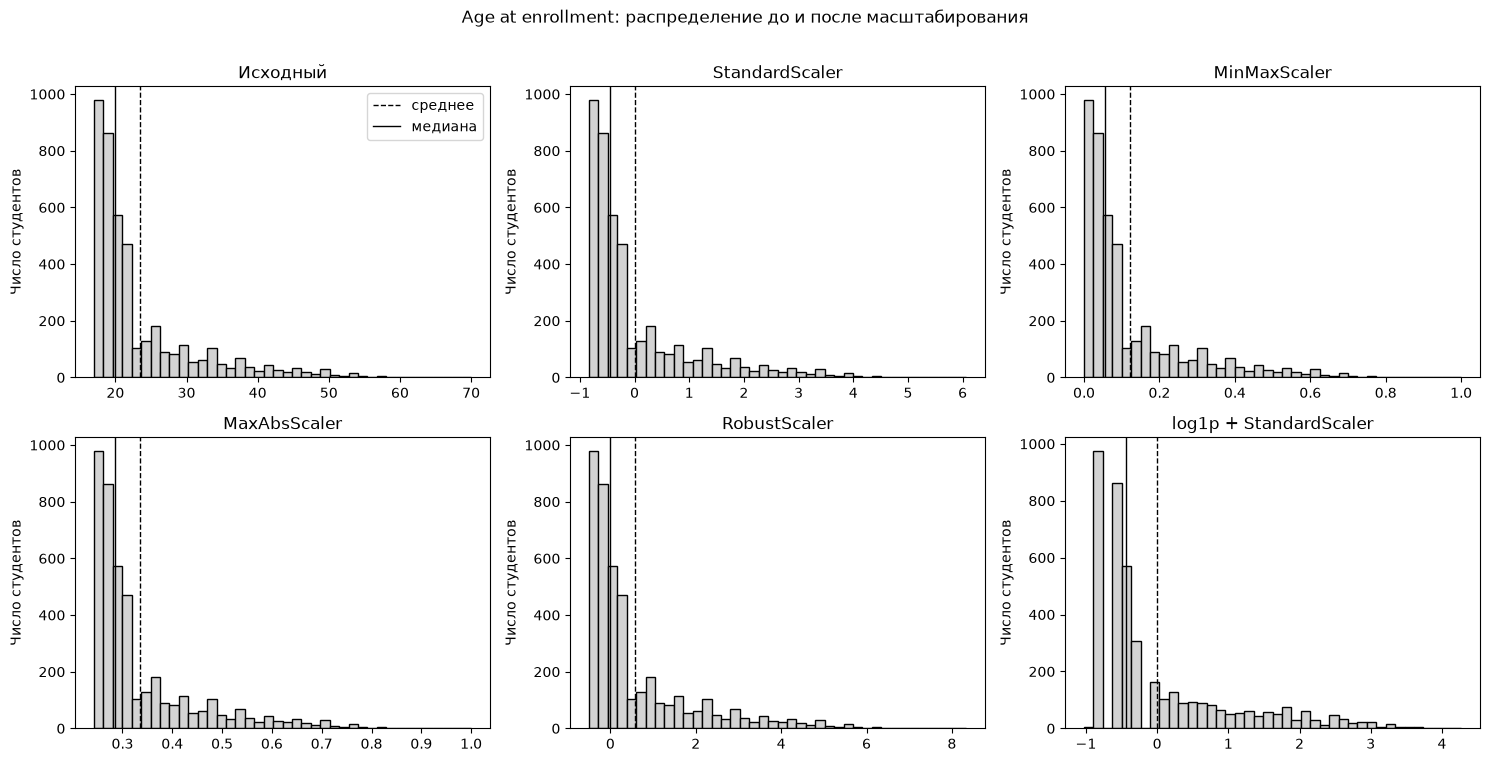

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, (name, vals) in zip(axes.ravel(), scaled.items()):
    ax.hist(vals, bins=40, color="lightgray", edgecolor="black")
    ax.axvline(np.mean(vals), color="black", linestyle="--", linewidth=1, label="среднее")
    ax.axvline(np.median(vals), color="black", linestyle="-", linewidth=1, label="медиана")
    ax.set_title(name)
    ax.set_ylabel("Число студентов")
axes[0, 0].legend()
plt.suptitle("Age at enrollment: распределение до и после масштабирования", y=1.01)
plt.tight_layout(); plt.show()

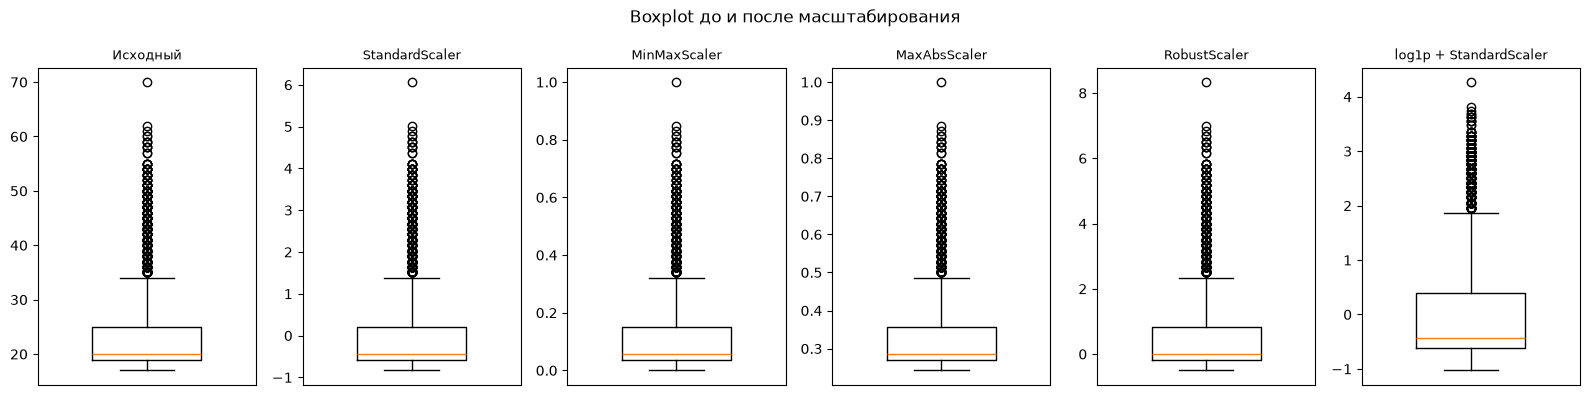

In [5]:
# Boxplot — на нём лучше видно, куда «уезжают» выбросы при каждом методе
fig, axes = plt.subplots(1, 6, figsize=(16, 4))
for ax, (name, vals) in zip(axes, scaled.items()):
    ax.boxplot(vals, widths=0.5)
    ax.set_title(name, fontsize=9)
    ax.set_xticks([])
plt.suptitle("Boxplot до и после масштабирования")
plt.tight_layout(); plt.show()

In [6]:
# Пример: как конкретные значения переходят в новые шкалы
examples = pd.DataFrame({"возраст": [17, 18, 20, 23, 30, 45, 70]})
rows = {}
for name, sc in scalers.items():
    rows[name] = sc.transform(examples[["возраст"]].rename(columns={"возраст": "Age at enrollment"})).ravel().round(2)
pd.concat([examples, pd.DataFrame(rows)], axis=1)

,возраст,StandardScaler,MinMaxScaler,MaxAbsScaler,RobustScaler,log1p + StandardScaler
0,17,-0.83,0.00,0.24,-0.50,-1.03
1,18,-0.70,0.02,0.26,-0.33,-0.82
2,20,-0.44,0.06,0.29,0.00,-0.43
3,23,-0.05,0.11,0.33,0.50,0.08
4,30,0.86,0.25,0.43,1.67,1.07
5,45,2.81,0.53,0.64,4.17,2.59
6,70,6.06,1.00,1.00,8.33,4.27


### 2.2 Чем отличаются методы

Общее: Standard, MinMax, MaxAbs и Robust линейные, поэтому гистограммы после них одинаковые, меняются только числа на оси. Выброс (70 лет) остаётся выбросом, масштабирование его не убирает (это было в лекции).

Различия:
- MinMax и MaxAbs зависят от максимума. Из-за студентов 70 лет почти все остальные (18-20 лет) сжимаются в маленький промежуток: 0.02-0.06 у MinMax и 0.26-0.29 у MaxAbs. Разница между 18 и 20 годами почти пропадает. MaxAbs вообще больше нужен для данных с нулями и отрицательными значениями, у возраста их нет.
- StandardScaler использует среднее и std, а они сдвинуты из-за хвоста (среднее 23.4, медиана 20). Поэтому обычный 20-летний студент получает -0.44. Работает, но хуже Robust.
- RobustScaler использует медиану и IQR, на них хвост не влияет. Медиана (20 лет) становится 0, а возраст от 19 до 25 лет переходит в промежуток от -0.17 до 0.83. 70 лет становится 8.3, но основная масса не сжимается.
- log1p + Standard единственный меняет форму: хвост сжимается (70 лет становится 4.3, а у Standard было 6.1), распределение ближе к симметричному.

Что выбрал: для возраста лучше всего RobustScaler. Выбросы тут настоящие (взрослые студенты), удалять их не надо, а Robust от них не зависит. Для линейных моделей можно попробовать логарифм. MinMax и MaxAbs здесь не подходят. Для деревьев масштабирование вообще не нужно.

## 3. Предобработка всех столбцов

### 3.1 Деление на train и test

In [7]:
X = df.drop(columns=["Target", "Dropout"])
y_text = df["Target"]

# LabelEncoder — для целевой переменной (как в лекции), а не для входных признаков
le = LabelEncoder()
y_3class = le.fit_transform(y_text)
print("Классы Target →", dict(zip(le.classes_, range(len(le.classes_)))))

# Для нашей задачи цель бинарная: Dropout = 1, остальное = 0
y = (y_text == "Dropout").astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("train:", X_train.shape, " test:", X_test.shape)
print("Доля Dropout: train =", round(y_train.mean(), 3), "| test =", round(y_test.mean(), 3))

Классы Target → {'Dropout': 0, 'Enrolled': 1, 'Graduate': 2}
train: (3392, 34)  test: (849, 34)
Доля Dropout: train = 0.316 | test = 0.316


### 3.2 Какие группы столбцов и что с ними делаю

Все 34 столбца записаны числами, но по смыслу они разные:

1. Бинарные (8 штук: Gender, Debtor, Scholarship holder, Displaced, International, Tuition fees up to date, Educational special needs, Daytime/evening attendance). Оставляю как есть, они и так 0 или 1.

2. Категории, записанные кодами (9 штук: Marital status, Application mode, Course, Previous qualification, Nacionality, образование и работа родителей). Делаю OneHotEncoder. Числа тут просто номера: курс 12 не "больше" курса 3. Если оставить числами, модель решит, что есть порядок. handle_unknown="ignore" нужен, чтобы не было ошибки, если в test попадётся новая категория. min_frequency=20 объединяет редкие категории (меньше 20 студентов) в одну, иначе было бы много столбцов почти из одних нулей.

3. Application order (номер приоритета заявления, 0-9). Тут порядок настоящий, поэтому оставляю числом и масштабирую вместе с числовыми.

4. Числовые с перекосом (возраст и 12 столбцов про предметы за 2 семестра). RobustScaler, потому что у них много нулей и длинный хвост, а Robust от выбросов не зависит (это видно в разделе 2).

5. Экономика (Unemployment rate, Inflation rate, GDP). StandardScaler, потому что выбросов у них нет и значений всего около 10 (по годам).

Текстовых столбцов нет, поэтому CountVectorizer и TF-IDF не нужны. Пропусков тоже нет.

In [8]:
# Делю столбцы на группы, у каждой группы будет свой способ обработки
binary_cols = ["Gender", "Debtor", "Scholarship holder", "Displaced", "International",
               "Tuition fees up to date", "Educational special needs", "Daytime/evening attendance"]  # бинарные (0/1)
nominal_cols = ["Marital status", "Application mode", "Course", "Previous qualification", "Nacionality",
                "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]  # категории, записанные кодами
ordinal_cols = ["Application order"]  # порядковый: номер приоритета заявления (0-9)
macro_cols = ["Unemployment rate", "Inflation rate", "GDP"]  # экономика страны в год поступления
skewed_cols = [c for c in X.columns if c not in binary_cols + nominal_cols + ordinal_cols + macro_cols]  # всё остальное: возраст и предметы

# Сколько столбцов попало в каждую группу
print("Бинарные:", len(binary_cols), "| Номинальные:", len(nominal_cols), "| Порядковые:", len(ordinal_cols),
      "| Скошенные числовые:", len(skewed_cols), "| Макро:", len(macro_cols))
# Проверка, что ни один столбец не потерялся: в сумме должно быть 34
assert len(binary_cols) + len(nominal_cols) + len(ordinal_cols) + len(skewed_cols) + len(macro_cols) == X.shape[1]
skewed_cols  # какие столбцы попали в скошенные числовые

Бинарные: 8 | Номинальные: 9 | Порядковые: 1 | Скошенные числовые: 13 | Макро: 3


['Age at enrollment',
 'Curricular units 1st sem (credited)',
 'Curricular units 1st sem (enrolled)',
 'Curricular units 1st sem (evaluations)',
 'Curricular units 1st sem (approved)',
 'Curricular units 1st sem (grade)',
 'Curricular units 1st sem (without evaluations)',
 'Curricular units 2nd sem (credited)',
 'Curricular units 2nd sem (enrolled)',
 'Curricular units 2nd sem (evaluations)',
 'Curricular units 2nd sem (approved)',
 'Curricular units 2nd sem (grade)',
 'Curricular units 2nd sem (without evaluations)']

In [9]:
# Сколько разных значений у каждого категориального столбца:
# one-hot сделает по отдельному столбцу на каждое значение
X_train[nominal_cols].nunique().sort_values(ascending=False)

Father's occupation       42
Father's qualification    34
Mother's occupation       31
Mother's qualification    29
Application mode          17
Course                    17
Previous qualification    17
Nacionality               17
Marital status             6
dtype: int64

In [10]:
# Для каждой группы столбцов задаю свой метод
preprocessor = ColumnTransformer(
    transformers=[
        ("binary",  "passthrough", binary_cols),  # бинарные оставляю как есть
        ("nominal", OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=False), nominal_cols),  # коды -> one-hot, категории реже 20 раз объединяются в одну
        ("skewed",  RobustScaler(), skewed_cols + ordinal_cols),  # числовые с перекосом -> RobustScaler (медиана и IQR)
        ("macro",   StandardScaler(), macro_cols),  # экономика -> StandardScaler (среднее и std)
    ],
    verbose_feature_names_out=False,  # чтобы в названиях столбцов не было приставок вроде skewed__
)

# fit только на train, transform — на обеих выборках
X_train_prep = preprocessor.fit_transform(X_train)  # запоминает параметры по train и преобразует train
X_test_prep  = preprocessor.transform(X_test)  # к test применяет те же параметры, ничего не пересчитывая

# После преобразования получается таблица без названий столбцов, возвращаю их
feature_names = preprocessor.get_feature_names_out()
X_train_prep = pd.DataFrame(X_train_prep, columns=feature_names, index=X_train.index)
X_test_prep  = pd.DataFrame(X_test_prep,  columns=feature_names, index=X_test.index)

# Сколько стало столбцов (выросло из-за one-hot)
print("До предобработки:", X_train.shape, "→ после:", X_train_prep.shape)
print("Тест:", X_test.shape, "→", X_test_prep.shape)
X_train_prep.head(3)

До предобработки: (3392, 34) → после: (3392, 115)
Тест: (849, 34) → (849, 115)


,Gender,Debtor,Scholarship holder,Displaced,International,Tuition fees up to date,Educational special needs,Daytime/evening attendance,Marital status_1,Marital status_2,Marital status_4,Marital status_infrequent_sklearn,Application mode_1,Application mode_4,Application mode_6,Application mode_7,Application mode_8,Application mode_9,Application mode_12,Application mode_13,Application mode_14,Application mode_15,Application mode_16,Application mode_17,Application mode_infrequent_sklearn,...,Father's occupation_6,Father's occupation_7,Father's occupation_8,Father's occupation_9,Father's occupation_10,Father's occupation_11,Father's occupation_12,Father's occupation_infrequent_sklearn,Age at enrollment,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Application order,Unemployment rate,Inflation rate,GDP
652,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.333333,0.879330,0.0,0.0,0.0,0.00,0.333333,-0.551190,0.0,0.0,0.432953,1.792081,-0.769749
3081,0.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.666667,0.0,1.0,2.000000,0.000000,-0.002181,0.0,1.0,1.0,1.75,0.000000,-0.134524,0.0,0.0,-1.000394,0.121579,1.537439
2274,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,2.000000,0.0,-1.0,0.333333,-1.666667,-5.766978,1.0,0.0,-0.5,-0.75,-1.666667,-5.134524,0.0,0.0,-0.811796,-1.476293,-1.398580


### 3.3 Проверка результата

In [11]:
# 1) Нет ли пропусков после преобразования
print("NaN в train:", X_train_prep.isna().sum().sum(), "| NaN в test:", X_test_prep.isna().sum().sum())

# 2) Параметры скейлеров взяты из train: медиана возраста в train после Robust = 0, в test — не обязательно
print("Медиана Age (train, после Robust):", round(X_train_prep["Age at enrollment"].median(), 3))
print("Медиана Age (test,  после Robust):", round(X_test_prep["Age at enrollment"].median(), 3))

# 3) Сколько столбцов дал one-hot и сколько редких категорий объединено
ohe = preprocessor.named_transformers_["nominal"]
print("One-hot столбцов:", len(ohe.get_feature_names_out()))
rare = {col: len(inf) for col, inf in zip(nominal_cols, ohe.infrequent_categories_) if inf is not None}
print("Редких категорий объединено в 'infrequent' по столбцам:", rare)

NaN в train: 0 | NaN в test: 0
Медиана Age (train, после Robust): 0.0
Медиана Age (test,  после Robust): 0.0
One-hot столбцов: 90
Редких категорий объединено в 'infrequent' по столбцам: {'Marital status': 3, 'Application mode': 5, 'Course': 1, 'Previous qualification': 10, 'Nacionality': 15, "Mother's qualification": 20, "Father's qualification": 25, "Mother's occupation": 20, "Father's occupation": 30}


In [12]:
# Сводка после предобработки: центр всех числовых признаков в нуле, бинарные не тронуты
desc = X_train_prep[skewed_cols + macro_cols + binary_cols[:3]].describe().T[["mean", "50%", "min", "max"]].round(2)
desc

,mean,50%,min,max
Age at enrollment,0.57,0.00,-0.50,8.33
Curricular units 1st sem (credited),0.75,0.00,0.00,20.00
Curricular units 1st sem (enrolled),0.54,0.00,-5.00,20.00
Curricular units 1st sem (evaluations),0.22,0.00,-2.67,12.33
Curricular units 1st sem (approved),-0.02,0.00,-1.67,7.00
Curricular units 1st sem (grade),-0.57,0.00,-5.77,3.04
Curricular units 1st sem (without evaluations),0.13,0.00,0.00,10.00
Curricular units 2nd sem (credited),0.57,0.00,0.00,18.00
Curricular units 2nd sem (enrolled),0.25,0.00,-2.50,8.50
Curricular units 2nd sem (evaluations),0.11,0.00,-2.00,5.00


У credited и without evaluations больше 75% значений равны 0, поэтому IQR = 0. В таком случае RobustScaler ничего не меняет (sklearn делит на 1). Это не страшно, эти признаки почти бинарные.

### 3.4 Сохраняю выборки

In [13]:
X_train_prep.assign(Dropout=y_train.values).to_csv("train_prep.csv", index=False)
X_test_prep.assign(Dropout=y_test.values).to_csv("test_prep.csv", index=False)
print("Сохранено: train_prep.csv", X_train_prep.shape, "| test_prep.csv", X_test_prep.shape)

Сохранено: train_prep.csv (3392, 115) | test_prep.csv (849, 115)


## 4. Вывод

1. Различия между методами. StandardScaler, MinMaxScaler, MaxAbsScaler и RobustScaler линейные: они меняют только шкалу, а форма распределения и выброс (70 лет) остаются. Отличаются они тем, на что опираются:
- MinMax и MaxAbs опираются на максимум, поэтому из-за студентов 70 лет основная масса (18-20 лет) сжимается в узкий промежуток (0.02-0.06 и 0.26-0.29);
- StandardScaler опирается на среднее и std, которые сдвинуты хвостом, поэтому обычный 20-летний студент получает -0.44;
- RobustScaler опирается на медиану и IQR, хвост на них не влияет: медиана становится 0, основная масса не сжимается;
- логарифм + StandardScaler единственный меняет форму распределения: хвост сжимается, распределение становится ближе к симметричному.

2. Какой метод подходит для возраста. Лучше всего RobustScaler. У возраста перекос вправо и выбросы, но выбросы настоящие (взрослые студенты), удалять их нельзя. RobustScaler от них не зависит и не сжимает основную массу. MinMax и MaxAbs не подходят из-за привязки к максимуму, StandardScaler работает хуже из-за сдвинутого среднего. Логарифм можно попробовать, если модель чувствительна к перекосу.

3. Предобработка остальных столбцов. Разделил данные 80/20 со stratify, все преобразования обучал только на train. Бинарные оставил как есть, 9 категориальных перевёл в one-hot (редкие объединил), Application order оставил числом, 13 числовых с перекосом через RobustScaler, 3 экономических через StandardScaler. Из 34 столбцов получилось 115 (90 из них one-hot), пропусков нет.